# 02 · Exploración y selección de las muestras

Este notebook corresponde a los **apartados 4.1.2 a 4.1.5** de la memoria. Cada sección lleva el número del apartado al que respalda, y cada tabla o figura se imprime con el mismo número que tiene en la memoria.

| | |
|---|---|
| **Entrada** | `results/01_info_loaded.csv` (notebook 01) |
| **Salida** | `results/02_final_selection.csv` (entrada del notebook 03), tablas `results/02_*.csv` y `results/figures/fig_genre_distribution.png` |

## 0. Configuración

Rutas del proyecto, lectura de los metadatos cargados en el notebook 01 y obtención del género principal, que es la parte del campo `style` anterior a la barra (por ejemplo, `funk/groove1` → `funk`).

In [47]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import pretty_midi

plt.style.use("default")
plt.rcParams["savefig.facecolor"] = "white"

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "groove"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_GENRES = ["funk", "jazz", "latin", "rock"]
SPLIT_ORDER = ["train", "validation", "test"]

info = pd.read_csv(RESULTS_DIR / "01_info_loaded.csv")
info["genre"] = info["style"].str.split("/").str[0]

print("Registros:", len(info))
print("Géneros principales distintos:", info["genre"].nunique())

Registros: 1150
Géneros principales distintos: 18


## 4.1.2. Distribución de géneros

### Figura 1. Distribución de interpretaciones por género principal

Se cuenta el número de interpretaciones (*beats* y *fills*) de cada género principal y se dibuja la Figura 1, en la que se destacan los cuatro géneros seleccionados.

Interpretaciones por género principal:


beat_type,beats,fills,total
genre,,,
rock,211,130,341
funk,53,107,160
jazz,50,51,101
latin,51,46,97
hiphop,34,61,95
soul,28,35,63
afrocuban,7,53,60
punk,7,51,58
neworleans,13,40,53


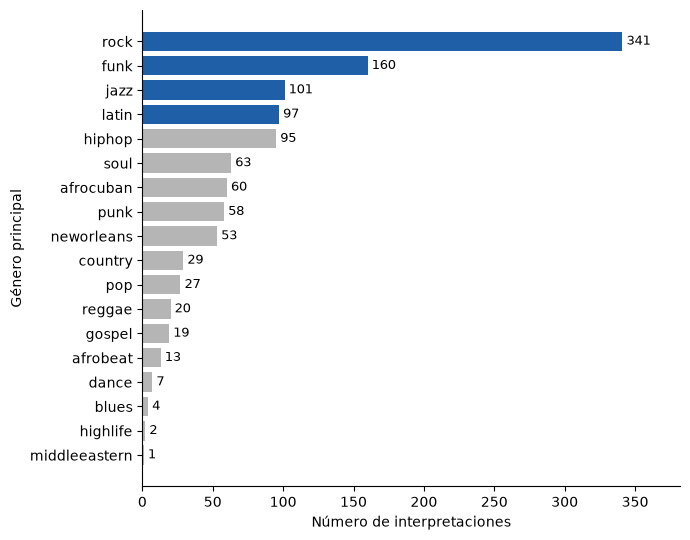

In [48]:
genre_table = (pd.crosstab(info["genre"], info["beat_type"])
                 .rename(columns={"beat": "beats", "fill": "fills"}))
genre_table["total"] = genre_table["beats"] + genre_table["fills"]
genre_table = genre_table.sort_values("total", ascending=False)
genre_table.to_csv(RESULTS_DIR / "02_genre_distribution.csv")

print("Interpretaciones por género principal:")
display(genre_table)

plot_data = genre_table.sort_values("total")
colors = ["#1f5fa8" if g in SELECTED_GENRES else "#b5b5b5" for g in plot_data.index]
fig, ax = plt.subplots(figsize=(7, 5.5))
bars = ax.barh(plot_data.index, plot_data["total"], color=colors)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_xlabel("Número de interpretaciones")
ax.set_ylabel("Género principal")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, plot_data["total"].max() * 1.12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_genre_distribution.png", dpi=300)
plt.show()

### Peso de los géneros seleccionados

Se comprueba que funk, jazz, latin y rock son los cuatro géneros con más interpretaciones y cuántas suman en conjunto.

In [49]:
ranking = {g: int(genre_table.index.get_loc(g)) + 1 for g in SELECTED_GENRES}
n_selected = int(genre_table.loc[SELECTED_GENRES, "total"].sum())

print("Posición de cada género seleccionado en el ranking:", ranking)
print("Interpretaciones de los cuatro géneros:", n_selected,
      f"({100 * n_selected / genre_table['total'].sum():.1f} % del corpus)")

Posición de cada género seleccionado en el ranking: {'funk': 2, 'jazz': 3, 'latin': 4, 'rock': 1}
Interpretaciones de los cuatro géneros: 699 (60.8 % del corpus)


## 4.1.3. Selección y depuración de las muestras

Se aplican los dos criterios de selección: (1) conservar los cuatro géneros elegidos y (2) conservar solo las interpretaciones en compás de 4/4. El resultado (`final`) es la selección final que se usa en el resto del trabajo.

In [50]:
sel = info[info["genre"].isin(SELECTED_GENRES)]

ts_table = (pd.crosstab(sel["time_signature"], sel["genre"])
              .reindex(columns=SELECTED_GENRES, fill_value=0))
ts_table["total"] = ts_table.sum(axis=1)
ts_table = ts_table.sort_values("total", ascending=False)
ts_table.to_csv(RESULTS_DIR / "02_time_signature.csv")

final = sel[sel["time_signature"] == "4-4"].copy()
removed = sel[sel["time_signature"] != "4-4"]
final.to_csv(RESULTS_DIR / "02_final_selection.csv", index=False)

print("Criterio 1 (cuatro géneros):", len(sel), "interpretaciones")
print("\nInterpretaciones por tipo de compás y género:")
display(ts_table)
print("Criterio 2 (compás de 4/4): se eliminan", len(removed), "interpretaciones",
      removed["split"].value_counts().to_dict())
print("Selección final:", len(final), "interpretaciones",
      final["beat_type"].value_counts().to_dict())

Criterio 1 (cuatro géneros): 699 interpretaciones

Interpretaciones por tipo de compás y género:


genre,funk,jazz,latin,rock,total
time_signature,,,,,
4-4,160,99,94,334,687
3-4,0,2,2,1,5
6-8,0,0,0,5,5
5-4,0,0,0,1,1
5-8,0,0,1,0,1


Criterio 2 (compás de 4/4): se eliminan 12 interpretaciones {'train': 10, 'validation': 2}
Selección final: 687 interpretaciones {'beat': 353, 'fill': 334}


## 4.1.4. Composición de las particiones

### Tabla 4. Distribución de la selección final por género y partición

Número de interpretaciones de cada género en cada partición y porcentaje que representa dentro de la partición.

In [51]:
final_counts = (pd.crosstab(final["genre"], final["split"], margins=True, margins_name="total")
                  .reindex(index=SELECTED_GENRES + ["total"], columns=SPLIT_ORDER + ["total"]))
final_pct = (100 * pd.crosstab(final["genre"], final["split"], normalize="columns")
                   .reindex(index=SELECTED_GENRES, columns=SPLIT_ORDER)).round(1)

final_counts.to_csv(RESULTS_DIR / "02_final_split_counts.csv")
final_pct.to_csv(RESULTS_DIR / "02_final_split_pct.csv")

print("Número de interpretaciones:")
display(final_counts)
print("Porcentaje de cada género dentro de la partición:")
display(final_pct)

Número de interpretaciones:


split,train,validation,test,total
genre,,,,
funk,122,15,23,160
jazz,77,14,8,99
latin,71,16,7,94
rock,269,34,31,334
total,539,79,69,687


Porcentaje de cada género dentro de la partición:


split,train,validation,test
genre,,,
funk,22.6,19.0,33.3
jazz,14.3,17.7,11.6
latin,13.2,20.3,10.1
rock,49.9,43.0,44.9


### Tabla 5. Fragmentos de tipo *beat* y *fill* por género y partición

In [52]:
final_beat_fill = (pd.crosstab([final["genre"], final["beat_type"]], final["split"])
                     .reindex(columns=SPLIT_ORDER, fill_value=0))
final_beat_fill.to_csv(RESULTS_DIR / "02_final_beat_fill_split.csv")
display(final_beat_fill)

split            train  validation  test
genre beat_type                         
funk  beat          31           6    16
      fill          91           9     7
jazz  beat          39           5     4
      fill          38           9     4
latin beat          36           9     3
      fill          35           7     4
rock  beat         167          16    21
      fill         102          18    10

### Interpretaciones de prueba procedentes de la sesión de evaluación

La partición de prueba incluye la sesión de evaluación del corpus (`eval_session`), en la que cuatro bateristas tocaron los mismos patrones. Se cuenta cuántas interpretaciones de prueba proceden de ella.

In [53]:
test = final[final["split"] == "test"]
from_eval = test[test["session"].str.contains("eval_session")]

print("Interpretaciones de prueba:", len(test))
print("Procedentes de eval_session:", len(from_eval), from_eval["genre"].value_counts().to_dict())

Interpretaciones de prueba: 69
Procedentes de eval_session: 16 {'funk': 12, 'rock': 4}


## 4.1.5. Representación de las muestras

### Tabla 6. Duración de las interpretaciones en compases

La duración en compases se calcula como: final de la última nota (s) × tempo (pulsos/min) / 60 / 4 pulsos por compás. Se usa el final de la última nota, y no el campo `duration`, por lo visto en la sección 4 del notebook 01.

In [54]:
def note_end_s(midi_path):
    pm = pretty_midi.PrettyMIDI(str(DATA_DIR / midi_path))
    return max(n.end for n in pm.instruments[0].notes)

final["note_end_s"] = final["midi_filename"].apply(note_end_s)
final["n_bars"] = final["note_end_s"] * final["bpm"] / 60 / 4
final[["id", "genre", "beat_type", "split", "bpm", "note_end_s", "n_bars"]].to_csv(
    RESULTS_DIR / "02_bars_per_file.csv", index=False)

bars_table = (final.groupby("beat_type")["n_bars"]
                   .agg(n="count", minimo="min", mediana="median",
                        percentil_75=lambda s: s.quantile(0.75), maximo="max")
                   .round(1))
display(bars_table)

print("Mediana de compases de los beats por género:")
print(final[final["beat_type"] == "beat"].groupby("genre")["n_bars"].median().round(1).to_string())

,n,minimo,mediana,percentil_75,maximo
beat_type,,,,,
beat,353,0.3,21.1,63.8,639.0
fill,334,0.5,0.9,1.0,11.8


Mediana de compases de los beats por género:
genre
funk     42.0
jazz     32.4
latin    67.7
rock     12.0


### Interpretaciones que alcanzan una longitud mínima

Número de interpretaciones que tienen al menos 2, 4 y 8 compases. Muestra cuántas se perderían si se dividieran en ventanas de esa longitud.

In [55]:
for w in [2, 4, 8]:
    print(f"Al menos {w} compases: {int((final['n_bars'] >= w).sum())} de {len(final)}")

Al menos 2 compases: 329 de 687
Al menos 4 compases: 288 de 687
Al menos 8 compases: 257 de 687
